# Lab 6: Linear Regression II
## Analyze Hypoxia Data
Before you turn this assignment in, make sure everything runs as expected. First, **restart the kernel** (in the menubar, select Kernel$\rightarrow$Restart) and then **run all cells** (in the menubar, select Cell$\rightarrow$Run All).

Add as many comments as you could when you solve the problem, which can help your remember what you have done.


***Submission***: For Python people, submit this Jupyter Notebook only

Name = "Noah Runions"

***Note:*** The functions/code provided are one of many ways that can work. Feel free to use functions you are more familiar with!\
***Figures:*** For any figures, label axis and title clearly for full points. 

## Lab Objectives:

1.	Understand underlying cause of hypoxia 
2.	Calculate linear regression variables, confidence intervals, and ANOVA table for TX_LA shelf hypoxia data
3.	Compare the regression models using the ANOVA parameters
4.	Data manipulation (adding data to existing data frame, data sorting)


  
## Lab Activities: 
This lab has two parts, A (30 points), B (20 points),and bonus questions (5 points). Be sure to follow the instructions and complete each parts. 

In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

## Part 6A (30 points). Linear Regression for hypoxia data without outliers

1. Go to Canvas to download hypoxia data, it contais four columns: Year, Mid-summer nitrate loading (metric tons/month), Hypoxia area (km2), and May river discharge (m3/s). 

Note:
- The data are extracted from Table 2 of the research article by Forrest, Hetland, and DiMarco (2011) 
(PDF file is available in Canvas. You will need to open and read the paper!
- The provided data set excludes the Years 1988 and 1989 as outliers. 
- Reference: Forrest, D. R., Hetland, R. D., & DiMarco, S. F. (2011). Multivariable statisticalregression models of the areal extent of hypoxia over the Texas–Louisiana continental shelf. Environmental Research Letters, 6(4), 45002. https://doi.org/10.1088/1748-9326/6/4/045002


In [2]:
hypoxia = pd.read_csv(r'C:\Users\noahr\Documents\Python Scripts\OCNG470\Lab6\lab6_data_hypoxia.txt', sep= "\t")
hypoxia

,Year,Area_km2,discharge_m3persecond,nitrate_mtpermonth
0,1985,9774,26200,112000
1,1986,9432,20500,121000
2,1987,6688,17800,87400
3,1990,9260,36000,146000
4,1991,11920,43600,189000
5,1992,10804,18600,104000
6,1993,17600,46200,214000
7,1994,16600,42100,130000
8,1995,18200,31300,142000
9,1996,17920,34600,146000


Plot the data and examine the trend visually
1.	Plot three time series in one figure (Figure 1). Please lable them clearly for full points. Lets plot these below either with subplots or three lines in the same figure with different colors
- Mid-summer nutrient loading time series
- May river discharge time series
- Hypoxia area time series



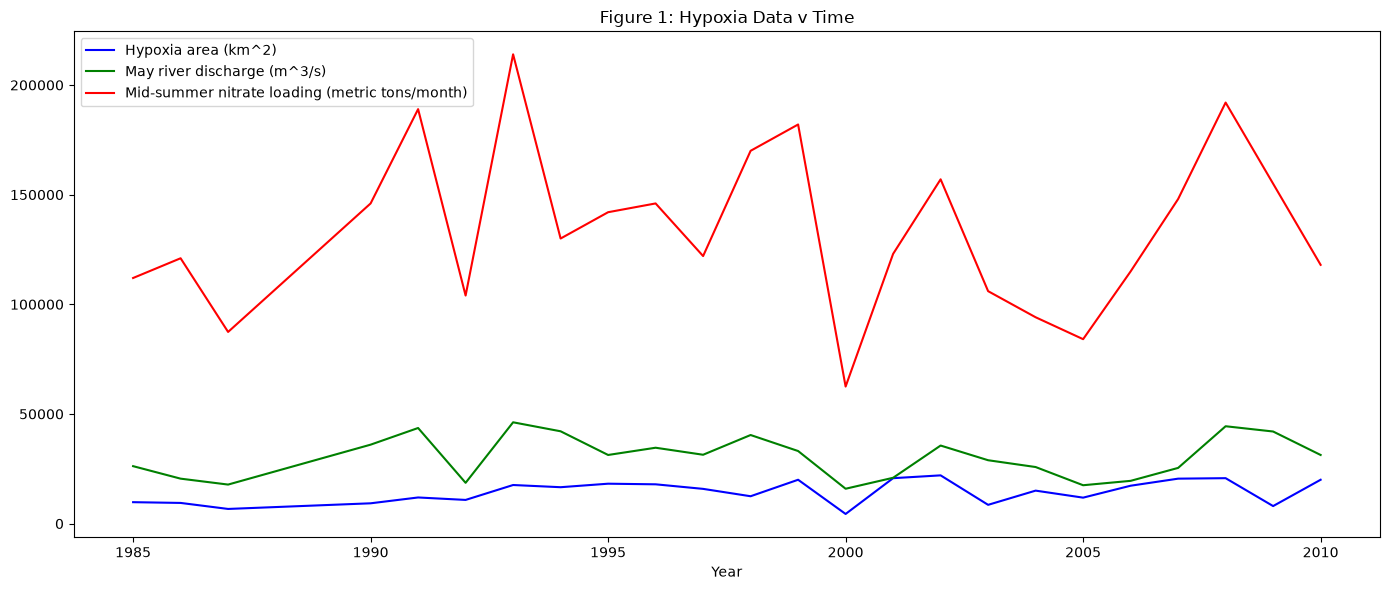

In [3]:
#Your code 
plt.figure(figsize=(14, 6))

# lineplots of data
sns.lineplot(x = 'Year', y='Area_km2', data=hypoxia, label='Hypoxia area (km^2)', color='b')
sns.lineplot(x = 'Year', y='discharge_m3persecond', data=hypoxia, label='May river discharge (m^3/s)', color='g')
sns.lineplot(x = 'Year', y='nitrate_mtpermonth', data=hypoxia, label='Mid-summer nitrate loading (metric tons/month)', color='r')

# labels
plt.xlabel('Year')
plt.ylabel('')
plt.title('Figure 1: Hypoxia Data v Time')
plt.legend()

# showing plot
plt.tight_layout()
plt.show()



2.	Visually examine the time series. Do you see a relationship between any of the three parameters? \
Type you answer:

The nutrient loading and discharge series seem to have the most direct relationship with similar peaks/troughs \
The hypoxia area series does not seem to fluctuate as much as the other two

3. Scatter plot and regression analysis (nitrate)

- Plot a scatter plot comparing mid-summer nutrient loading on x and hypoxia area on y for Figure 2. Add linear regression plot with 95% confidence interval Label them for full points. 
- Linear regression analysis: 
- Estimate the linear regression parameters and get the anova table for the two variables plotted in Figure 2.


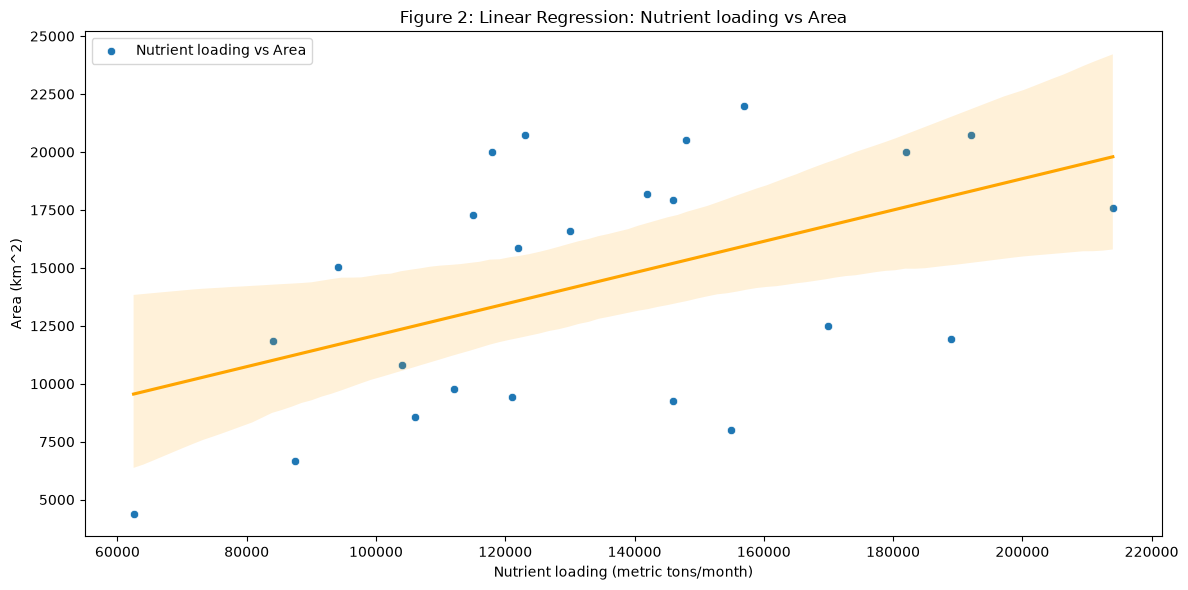

In [4]:
plt.figure(figsize=(12, 6))
sns.scatterplot(data=hypoxia, x= 'nitrate_mtpermonth', y= 'Area_km2', label='Nutrient loading vs Area'  )
sns.regplot(data=hypoxia, x= 'nitrate_mtpermonth', y= 'Area_km2', label='Nutrient loading vs Area' , ci=95, scatter=False, color='orange' )
plt.xlabel('Nutrient loading (metric tons/month)')
plt.ylabel('Area (km^2)')
plt.title('Figure 2: Linear Regression: Nutrient loading vs Area')

plt.tight_layout()
plt.show()

In [5]:
(slope1, int1, r1, p1, ster1) = stats.linregress(hypoxia['Area_km2'], hypoxia['nitrate_mtpermonth'])
print('Slope:', slope1)
print('Intercept:', int1)
print('r-value:', r1)
print('p-value:', p1)
print()

modela = ols('nitrate_mtpermonth ~ Area_km2', data=hypoxia).fit()
print(modela.summary())

Slope: 3.5061247416282475
Intercept: 83685.85100156639
r-value: 0.4867904655922994
p-value: 0.015851120388591208

                            OLS Regression Results                            
Dep. Variable:     nitrate_mtpermonth   R-squared:                       0.237
Model:                            OLS   Adj. R-squared:                  0.202
Method:                 Least Squares   F-statistic:                     6.832
Date:                Wed, 14 Oct 2026   Prob (F-statistic):             0.0159
Time:                        23:26:43   Log-Likelihood:                -283.13
No. Observations:                  24   AIC:                             570.3
Df Residuals:                      22   BIC:                             572.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------

4. Scatter plot and regression analysis (discharge)

- Plot a scatter plot comparing river discharge on x and hypoxia area on y for Figure 3. Add linear regression plot with 95% confidence interval Label them for full points. 
- Linear regression analysis: 
- Estimate the linear regression parameters and get the anova table for the two variables plotted in Figure 3.



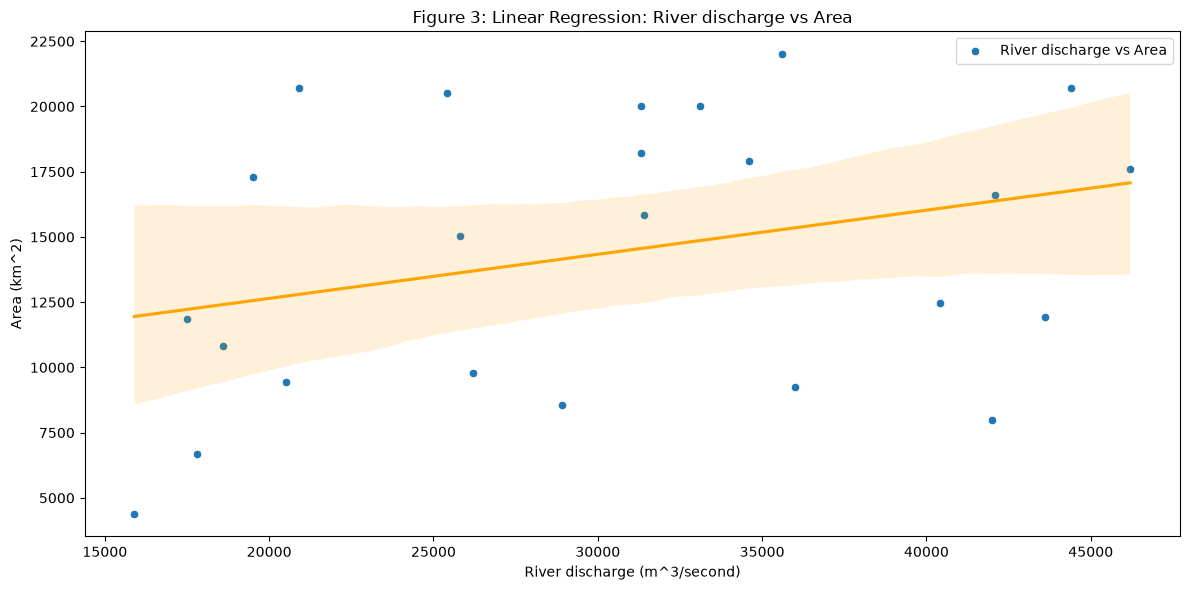

In [6]:
plt.figure(figsize=(12, 6))
sns.scatterplot(data=hypoxia, x= 'discharge_m3persecond', y= 'Area_km2', label='River discharge vs Area'  )
sns.regplot(data=hypoxia, x= 'discharge_m3persecond', y= 'Area_km2', label='River discharge vs Area' , ci=95, scatter=False, color='orange' )
plt.xlabel('River discharge (m^3/second)')
plt.ylabel('Area (km^2)')
plt.title('Figure 3: Linear Regression: River discharge vs Area')

plt.tight_layout()
plt.show()

In [7]:
(slope2, int2, r2, p2, ster2) = stats.linregress(hypoxia['Area_km2'], hypoxia['discharge_m3persecond'])
print('Slope:', slope2)
print('Intercept:', int2)
print('r-value:', r2)
print('p-value:', p2)
print()

modelb = ols('discharge_m3persecond ~ Area_km2', data=hypoxia).fit()
print(modelb.summary())

Slope: 0.5733374790777026
Intercept: 22119.465860636905
r-value: 0.31133667160591305
p-value: 0.13863239075176864

                              OLS Regression Results                             
Dep. Variable:     discharge_m3persecond   R-squared:                       0.097
Model:                               OLS   Adj. R-squared:                  0.056
Method:                    Least Squares   F-statistic:                     2.361
Date:                   Wed, 14 Oct 2026   Prob (F-statistic):              0.139
Time:                           23:26:43   Log-Likelihood:                -252.42
No. Observations:                     24   AIC:                             508.8
Df Residuals:                         22   BIC:                             511.2
Df Model:                              1                                         
Covariance Type:               nonrobust                                         
                 coef    std err          t      P>|t|      [0.02

5.	Compare the correlation between nutrient vs hypoxia area and the correlation between river discharge vs hypoxia area. Will nutrient or river discharge help the prediction better? Explain why such relationship is observed by relating them to the hypoxia process talked in the lab.
 Discuss the trend observed through the scatter plot, the coefficients of determinants, F ratio and p values, etc

- Type in your answer:

Nutrient loading will help the prediction better. It has a higher R^2 value (accounts for more varience), a higher F ratio (more likely to reject a null hypothesis), and a lower p value (less likely for the correlation to be random chance)

## Part 6B (20 pints); Hypoxia data with outlier data
1.	Create a second data table by copy the table from part A.
- Add a new row into the new data table that contain data from year 1988 then sort the data by the year column
- You can get the data from the reference (Table 2)


In [8]:
hypoxia_copy = hypoxia.copy()
new_data = pd.DataFrame({
    'Year': [1988],
    'nitrate_mtpermonth': [50500],
    'discharge_m3persecond': [13400],
    'Area_km2': [40]
})
hypoxia_full = pd.concat([hypoxia_copy, new_data], ignore_index=True)
hypoxia_full = hypoxia_full.sort_values(by='Year')
print(hypoxia_full)

    Year  Area_km2  discharge_m3persecond  nitrate_mtpermonth
0   1985      9774                  26200              112000
1   1986      9432                  20500              121000
2   1987      6688                  17800               87400
24  1988        40                  13400               50500
3   1990      9260                  36000              146000
4   1991     11920                  43600              189000
5   1992     10804                  18600              104000
6   1993     17600                  46200              214000
7   1994     16600                  42100              130000
8   1995     18200                  31300              142000
9   1996     17920                  34600              146000
10  1997     15840                  31400              122000
11  1998     12480                  40400              170000
12  1999     20000                  33100              182000
13  2000      4400                  15900               62500
14  2001

2.	Perform linear regression analysis as you did in Part A between mid summer nutrient loading (on x) and hypoxia area (on y) from years 1985 to 1996.
- You need to extract the year between 1985 to 1996
- You should get:
- Figure 4: scatter plot with nutrient vs hypoxia area, linear regression line and 95% confidence interval. Label the graph clearly.
- Linear regression model parameters and ANOVA parameter. Display them by using print()




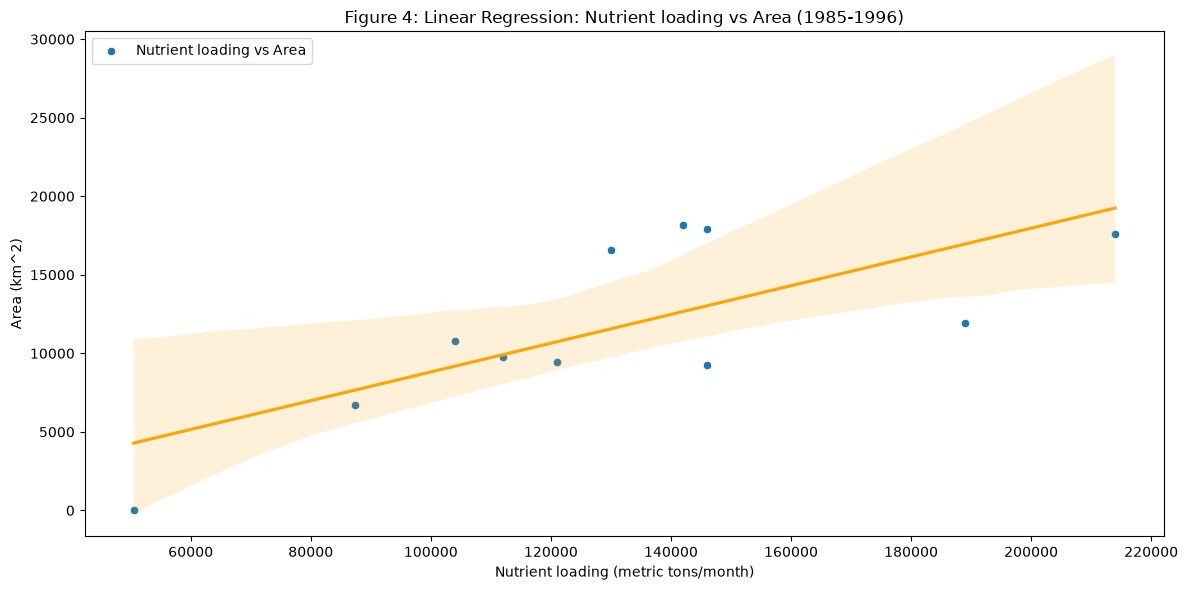

In [9]:
hypoxia_85_96 = hypoxia_full[(hypoxia_full['Year'] >= 1985) & (hypoxia_full['Year'] <= 1996)]

plt.figure(figsize=(12, 6))
sns.scatterplot(data=hypoxia_85_96, x= 'nitrate_mtpermonth', y= 'Area_km2', label='Nutrient loading vs Area'  )
sns.regplot(data=hypoxia_85_96, x= 'nitrate_mtpermonth', y= 'Area_km2', label='Nutrient loading vs Area' , ci=95, scatter=False, color='orange' )
plt.xlabel('Nutrient loading (metric tons/month)')
plt.ylabel('Area (km^2)')
plt.title('Figure 4: Linear Regression: Nutrient loading vs Area (1985-1996)')

plt.tight_layout()
plt.show()

In [10]:
(slope3, int3, r3, p3, ster3) = stats.linregress(hypoxia_85_96['Area_km2'], hypoxia_85_96['nitrate_mtpermonth'])
print('Slope:', slope3)
print('Intercept:', int3)
print('r-value:', r3)
print('p-value:', p3)
print()

modelc = ols('nitrate_mtpermonth ~ Area_km2', data=hypoxia_85_96).fit()
print(modelc.summary())

Slope: 5.89755792515741
Intercept: 62328.08789033309
r-value: 0.7346263383004324
p-value: 0.01002463057423307

                            OLS Regression Results                            
Dep. Variable:     nitrate_mtpermonth   R-squared:                       0.540
Model:                            OLS   Adj. R-squared:                  0.489
Method:                 Least Squares   F-statistic:                     10.55
Date:                Wed, 14 Oct 2026   Prob (F-statistic):             0.0100
Time:                        23:26:43   Log-Likelihood:                -128.72
No. Observations:                  11   AIC:                             261.4
Df Residuals:                       9   BIC:                             262.2
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------

3.	Discuss the differences in the statistics for the 1985-2010 case (Figure 2) versus the 1985-1996 case (Figure 4). Use the trends in plots, and the numbers from the regression and ANOVA to support. Relate them to the hypoxia process talked in the lab. 

The 1985-1996 data set exhibited a higher R^2 value (accounts for more varience), a higher F ratio (more likely to reject a null hypothesis), and a lower p value (less likely for the correlation to be random chance). \
This better fit of linear regression is likely due to the fact that there is less data being represented. Even though the apparent outlier of the 1988 year was added back in, the restriction of years included meant that a linear regression trendline would fit better on the limited data

Bonus Questions (5 points)
1)	Why the data from 1989 were exclude from the regression analysis in Part B \
It was a partial, late season survey
2)	Why the reference paper decided to exclude the data from 1988 from the regression analysis ? (Hint, the answers for both can be found in the paper). \
The inclusion of the 1988 data disproportionaltely affected relation coeffecients and the data that year was collected later than usual
